---
title: "Figures: The Abel (1981)-Hayashi (1982) Marginal q Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=qModel.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/investment/qModel/qModel.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/investment/qModel/qModel.ipynb).

In [the Abel-Hayashi model](https://intertemporal-choice.github.io/content/investment/qmodel), a firm with capital $k_{t}$ chooses its net investment rate $\iota_{t} = i_{t}/k_{t} - \delta$, paying costs of adjustment $j = (k/2)\omega\iota^{2}$. Investment made at $t$ is paid for at $t+1$'s after-tax price of capital, $\mathscr{P}_{t+1}$, which is $1-\zeta$ when the investment tax credit is $\zeta$, and becomes productive at $t+1$. The chapter's equations are

$$
\begin{aligned}
k_{t+1} &= (1+\iota_{t})k_{t} && \text{(accumulation)} \\
1+\omega\iota_{t} &= \lambda_{t+1}/\mathscr{P}_{t+1} && \text{(first order condition)} \\
\lambda_{t} &= (1-\tau)\mathrm{f}^{k}(k_{t}) + \omega(\iota_{t}^{2}/2+\iota_{t}\delta)\mathscr{P}_{t+1}\beta + \beta(1-\delta)\lambda_{t+1} && \text{(envelope condition)}
\end{aligned}
$$

where $\lambda_{t}$ is the marginal value of a unit of capital, $\tau$ is the corporate tax rate, $\mathrm{f}(k) = Ak^{\alpha}$, and $\beta = 1/(1+r)$. In a steady state $\iota = 0$ and $\lambda = \mathscr{P}$, so marginal $q = \lambda/\mathscr{P}$ is one.

The chapter works with approximations, such as treating the product of two small rates as zero. This notebook solves the equations exactly, for a hundred periods at once: given the capital the firm starts with, and $\lambda$ at the end, in the new steady state, Newton's method finds the paths of $\lambda$ and $k$ that satisfy every equation in every period.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt

from intertemporal_choice import qmodel, style

style.use_book_style()

## The model

`q_model` returns the chapter's equations for given values of the interest rate and the depreciation rate. `residuals` stacks them for every period: `x` holds $\lambda_{0}, \ldots, \lambda_{T}$ and $k_{1}, \ldots, k_{T}$, and the paths of the after-tax share $1-\tau$, the price $\mathscr{P}$ and productivity $A$ say what changes and when. `stationary` is the locus where $\lambda$ is constant, $\lambda_{t+1} = \lambda_{t}$ in the envelope condition, with the effect of capital on the costs of adjustment set aside, as the chapter does near the steady state: $\lambda = (1-\tau)\mathrm{f}^{k}(k)/(1-\beta(1-\delta))$. Only that locus uses the approximation; the paths, and the saddle paths, are exact.

In [ ]:
def q_model(rate=0.04, delta=0.10, alpha=0.30):
    """The chapter's equations, with the interest rate and the depreciation rate given."""
    beta = 1 / (1 + rate)

    def iota(lam_next, P_next, omega):  # the first order condition: 1 + omega iota_t = lambda_{t+1} / P_{t+1}
        return (lam_next / P_next - 1) / omega

    def marginal_product(k, A):
        return A * alpha * k ** (alpha - 1)

    def steady_state(tax_free, P, A):  # iota = 0 and lambda = P: (1 - tau) f'(k) = (1 - beta (1 - delta)) P
        return (P * (1 - beta * (1 - delta)) / (tax_free * A * alpha)) ** (1 / (alpha - 1)), P

    def residuals(x, k0, tax_free, P, A, omega):
        T = len(P) - 1
        lam, k = x[:T + 1], np.concatenate([[k0], x[T + 1:]])
        i = iota(lam[1:], P[1:], omega)
        accumulation = k[1:] - (1 + i) * k[:-1]
        envelope = lam[:-1] - (tax_free[:-1] * marginal_product(k[:-1], A[:-1])
                               + omega * (i**2 / 2 + i * delta) * P[1:] * beta + beta * (1 - delta) * lam[1:])
        terminal = lam[-1] - steady_state(tax_free[-1], P[-1], A[-1])[1]
        return np.concatenate([accumulation, envelope, [terminal]])

    def stationary(k, tax_free, P, A, omega):  # lambda_{t+1} = lambda_t, setting j^k aside as the chapter does
        return tax_free * marginal_product(k, A) / (1 - beta * (1 - delta))

    return SimpleNamespace(iota=iota, steady_state=steady_state, residuals=residuals, stationary=stationary)

The calibration: a capital share of 0.3, an interest rate of 4 percent, depreciation of 10 percent and an adjustment cost $\omega$ of 2, a period being a year; a corporate tax rate of 30 percent, no investment tax credit, and productivity normalized to one.

In [ ]:
model = q_model(rate=0.04, delta=0.10)
omega = 2.0
before = {"tax_free": 1 - 0.30, "P": 1 - 0.0, "A": 1.0}  # 1 - tau, the after-ITC price 1 - zeta, and productivity

## The phase diagrams

In $(k, \lambda)$ and in $(k, q)$, here with an investment tax credit of 10 percent, so that $\mathscr{P} = 0.9$ and the line where capital is constant, $\lambda = \mathscr{P}$, sits below the steady state of the diagram in $q$, where it is always $q = 1$. Above that line the firm invests more than depreciation, so capital grows; above the locus where $\lambda$ is constant, $\lambda$ rises. The saddle path is the only path that reaches the steady state.

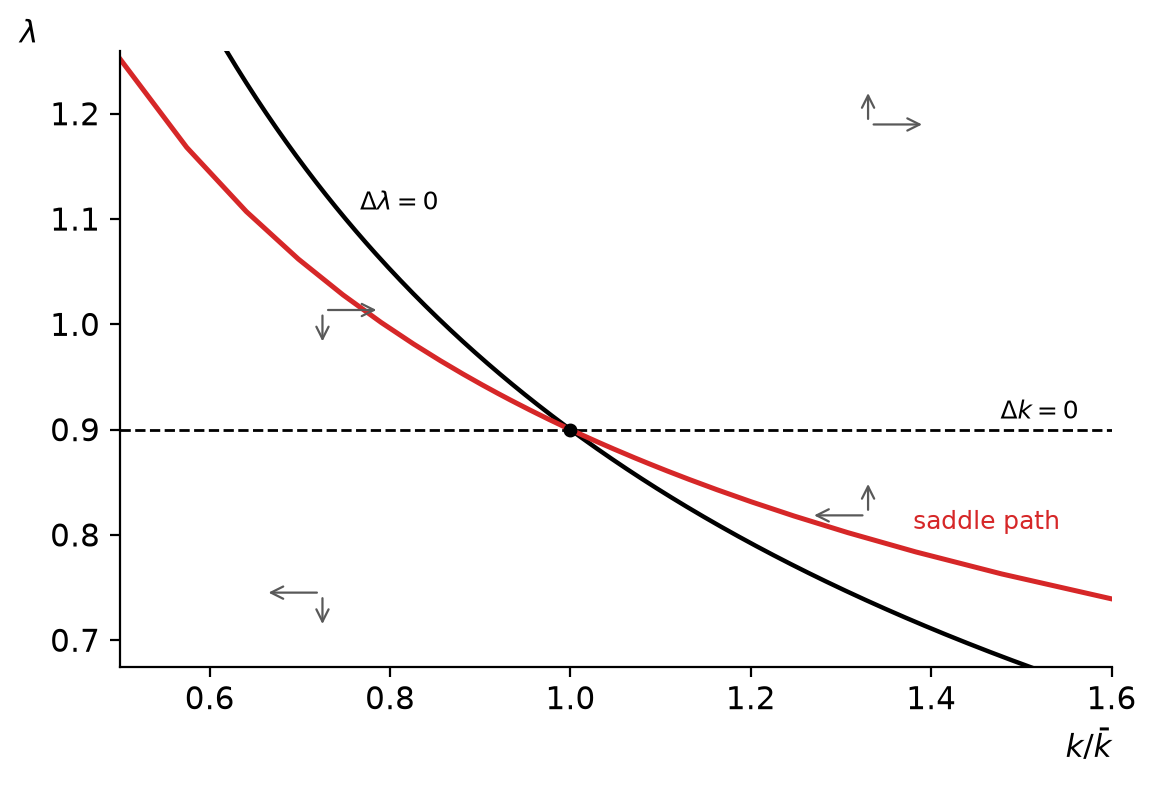

In [ ]:
with_itc = {**before, "P": 1 - 0.10}
fig, ax = plt.subplots()
qmodel.draw_phase(ax, model, with_itc, omega)
style.save(fig, "lPhaseDiag")

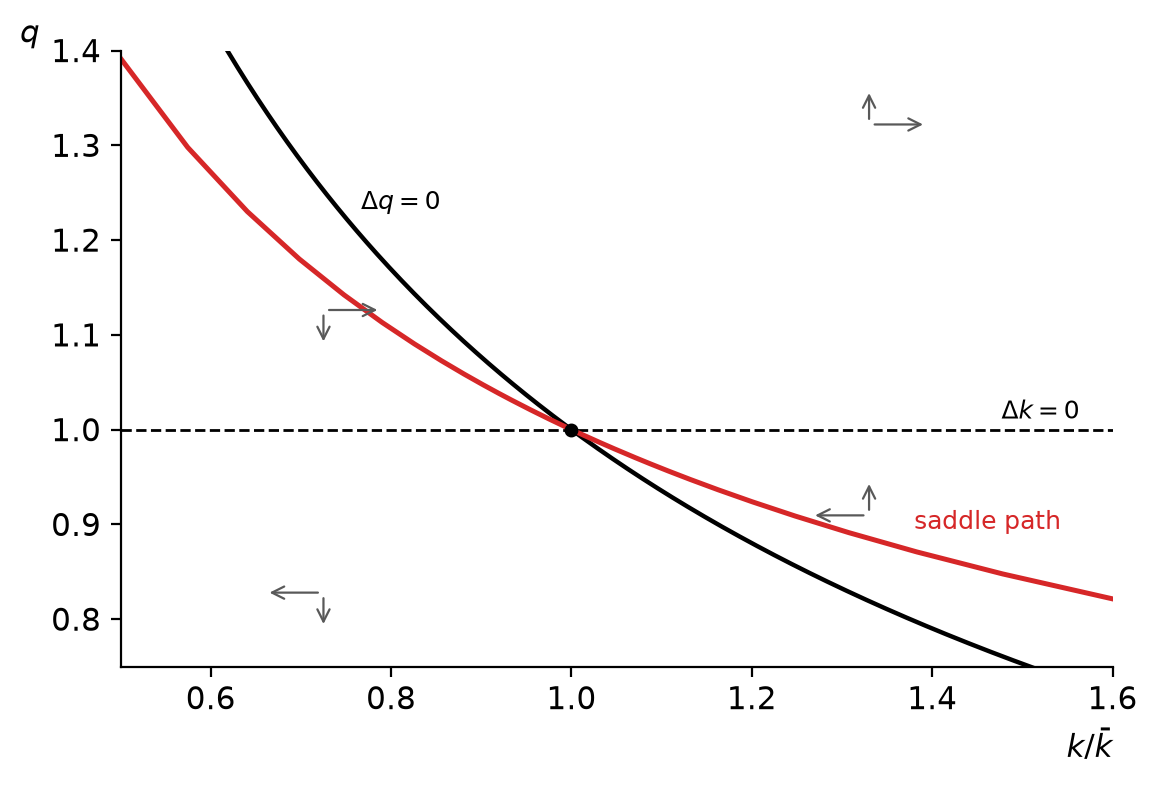

In [ ]:
fig, ax = plt.subplots()
qmodel.draw_phase(ax, model, with_itc, omega, scale="q")
style.save(fig, "qPhaseDiag")

## The chapter's experiments

Each is announced at date 0, unexpectedly, and takes effect at date $n$: at once, $n = 0$, or five periods later, $n = 5$. Top left, the phase diagram in $(k, \lambda)$ before the change (gray, dashed) and after it (black and red), with the path the economy takes, a dot a period; then, by period, the net investment rate $\iota$, $\lambda$ and $q$, and capital relative to its old steady state.

In [ ]:
experiments = {
    "ProductivityIncrease": ({**before, "A": 1.10}, 0),           # productivity up 10 percent, at once
    "CorporateTaxReduction": ({**before, "tax_free": 1 - 0.20}, 0),  # the corporate tax from 30 to 20 percent
    "ITCIncrease": ({**before, "P": 1 - 0.10}, 0),                # an investment tax credit of 10 percent
    "FutureProductivityIncrease": ({**before, "A": 1.10}, 5),     # the same rise in productivity, 5 periods ahead
    "FutureCorporateTaxReduction": ({**before, "tax_free": 1 - 0.20}, 5),  # the same tax cut, 5 periods ahead
    "FutureITCIncrease": ({**before, "P": 1 - 0.10}, 5),          # the same credit, 5 periods ahead
}
paths = {name: qmodel.solve(model, before, after, lead, omega) for name, (after, lead) in experiments.items()}

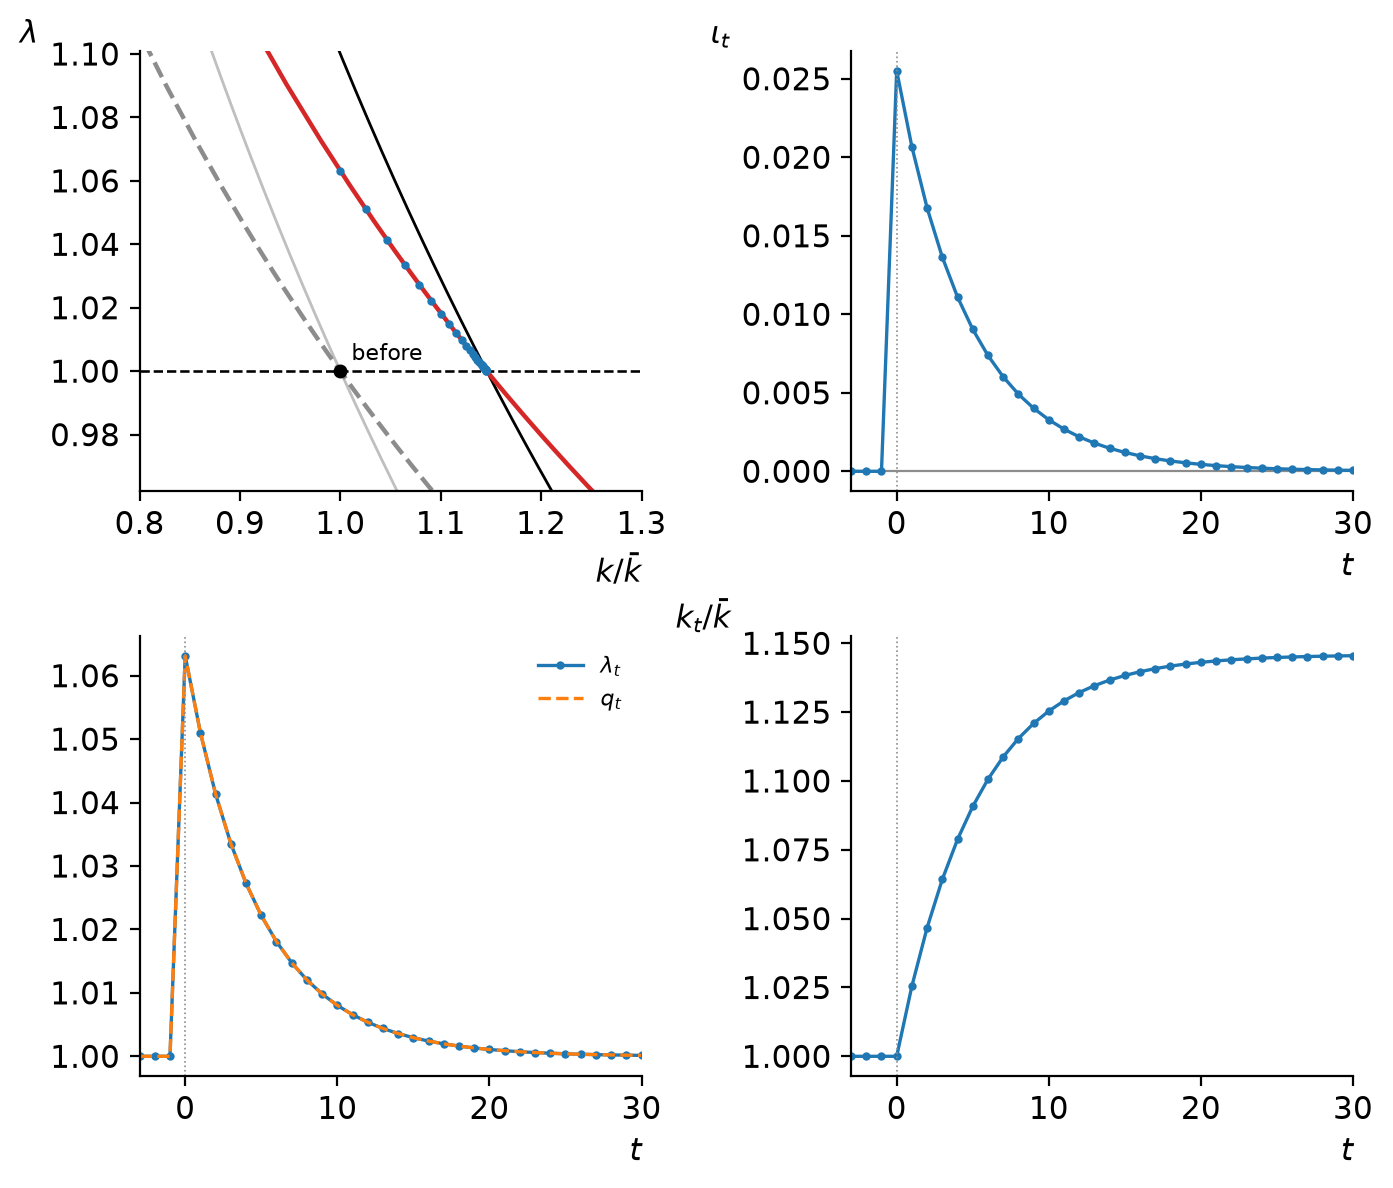

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["ProductivityIncrease"], omega)
fig.tight_layout()
style.save(fig, "ProductivityIncrease")

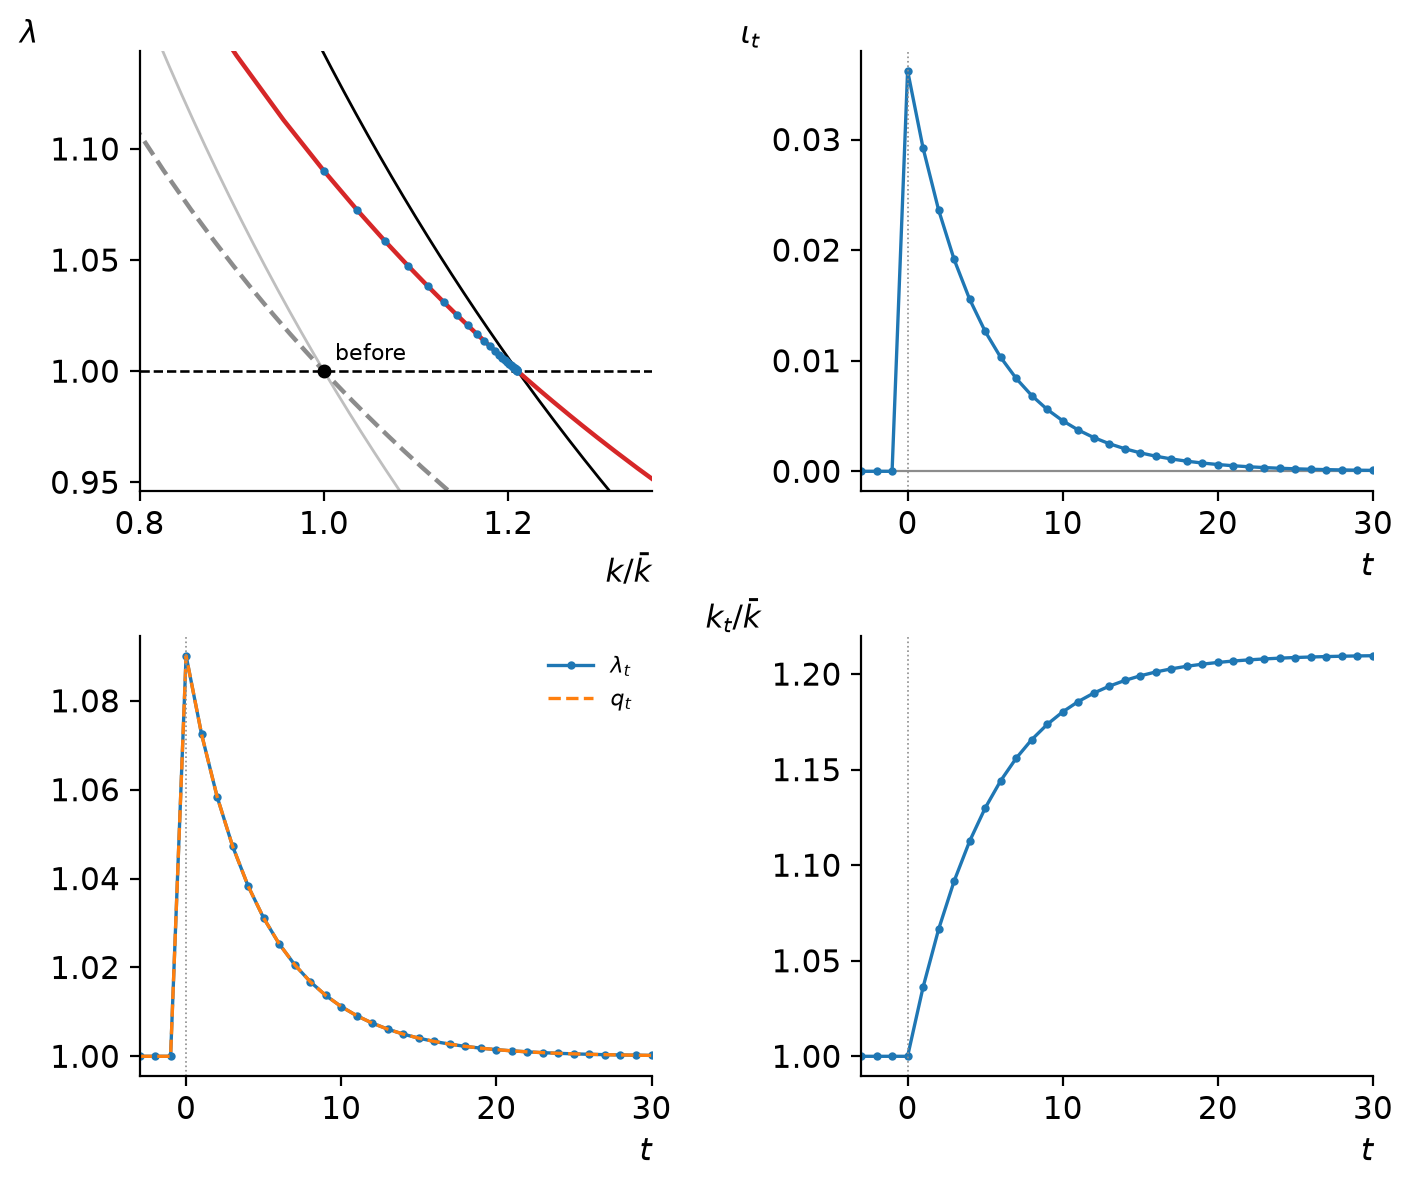

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["CorporateTaxReduction"], omega)
fig.tight_layout()
style.save(fig, "CorporateTaxReduction")

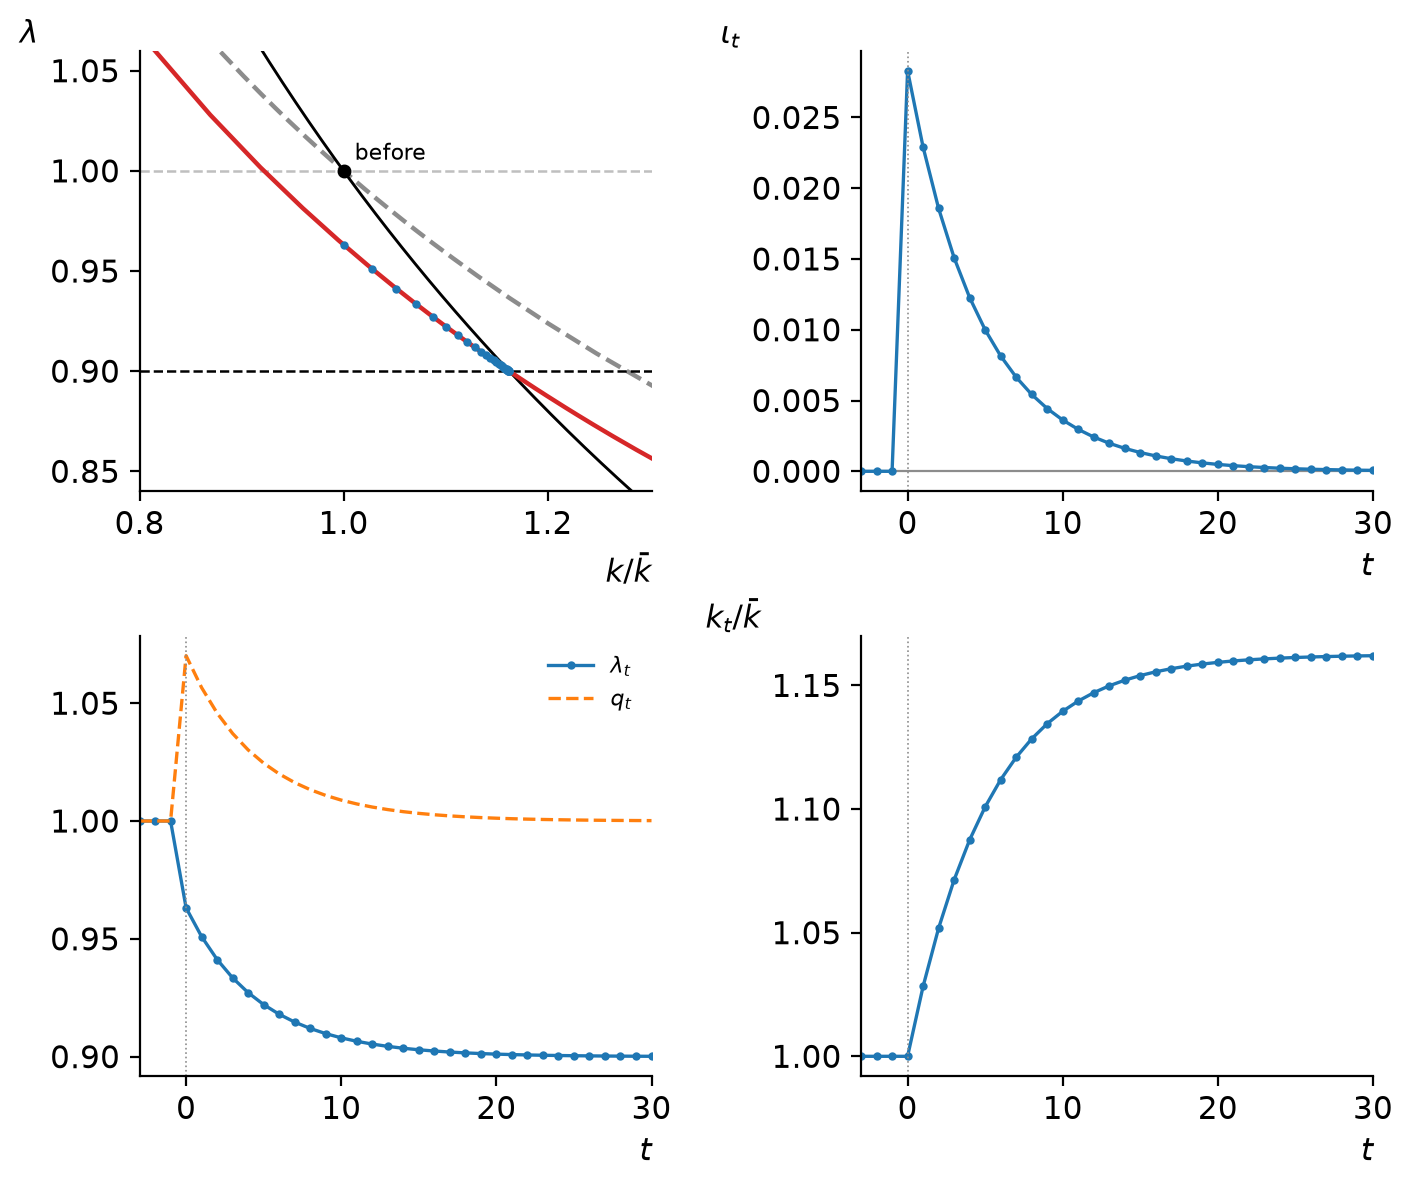

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["ITCIncrease"], omega)
fig.tight_layout()
style.save(fig, "ITCIncrease")

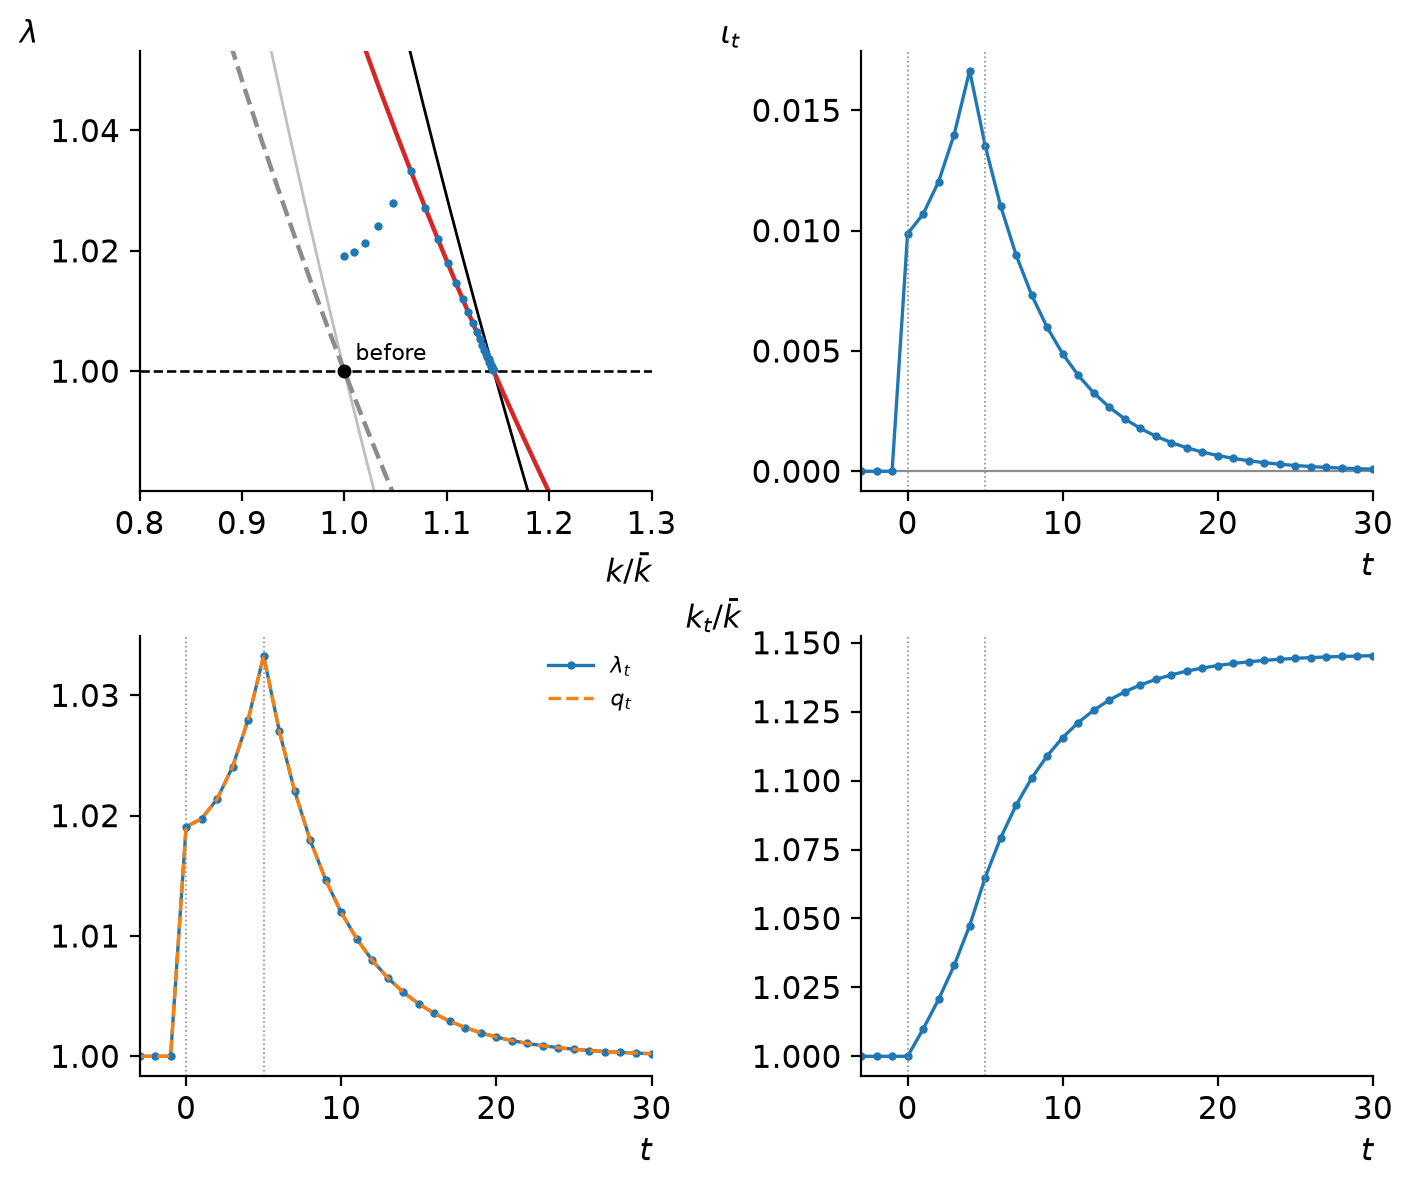

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["FutureProductivityIncrease"], omega)
fig.tight_layout()
style.save(fig, "FutureProductivityIncrease")

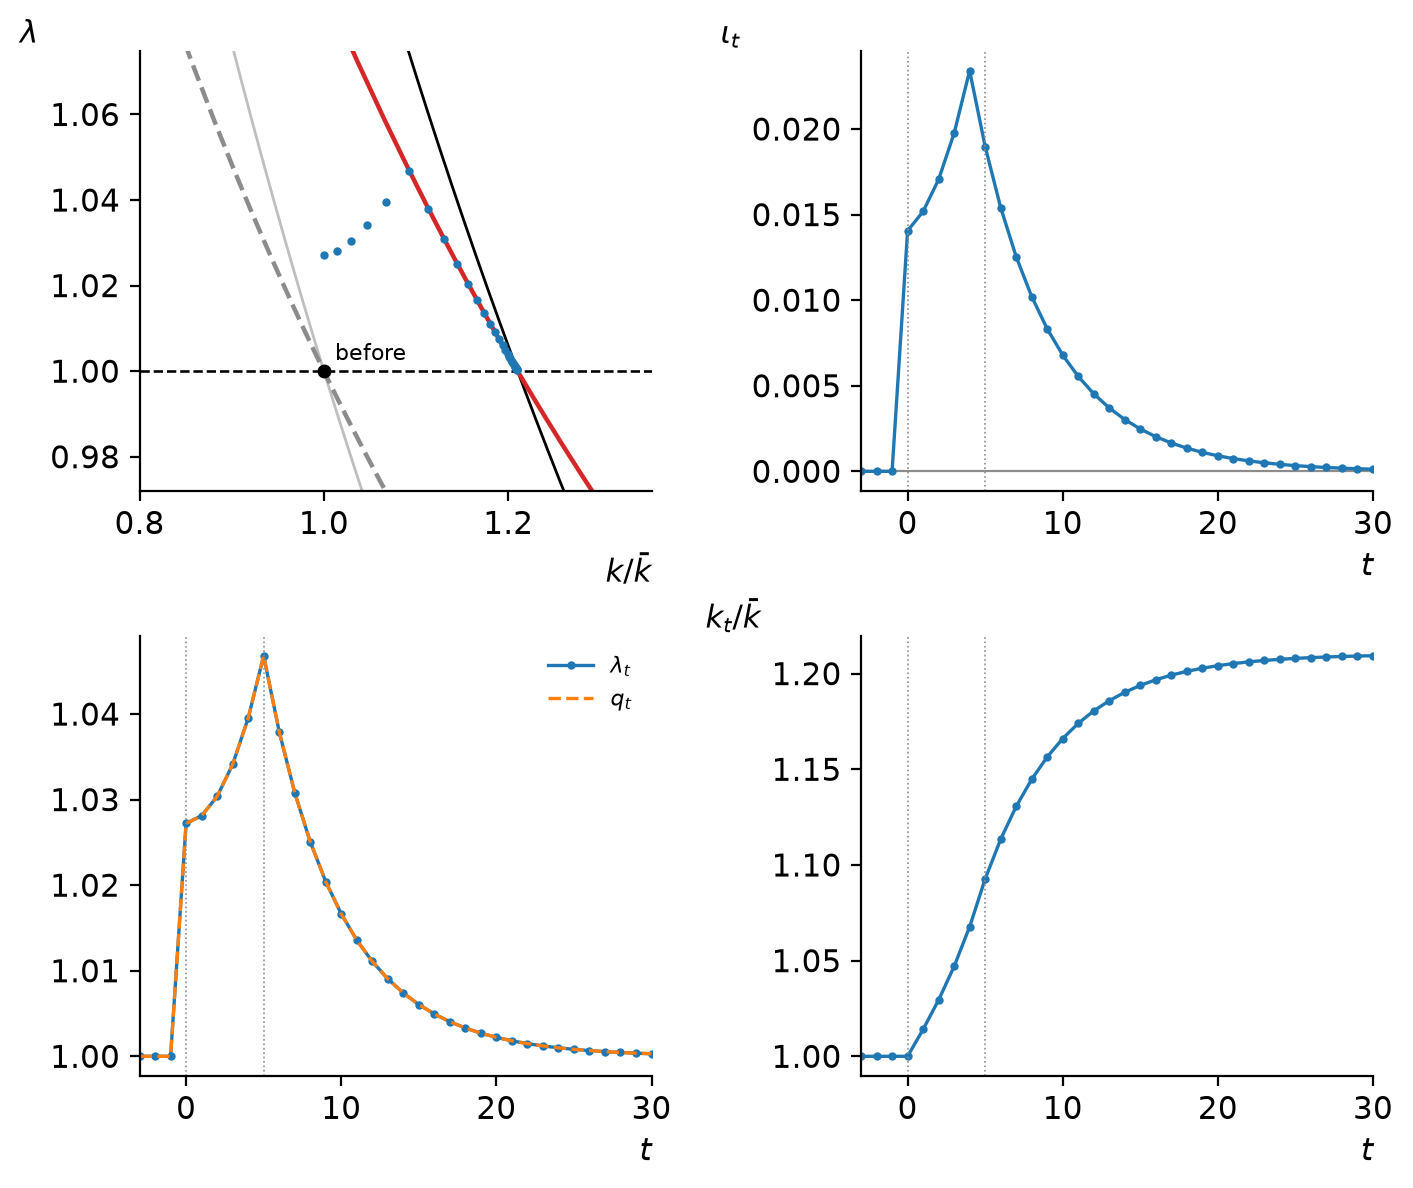

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["FutureCorporateTaxReduction"], omega)
fig.tight_layout()
style.save(fig, "FutureCorporateTaxReduction")

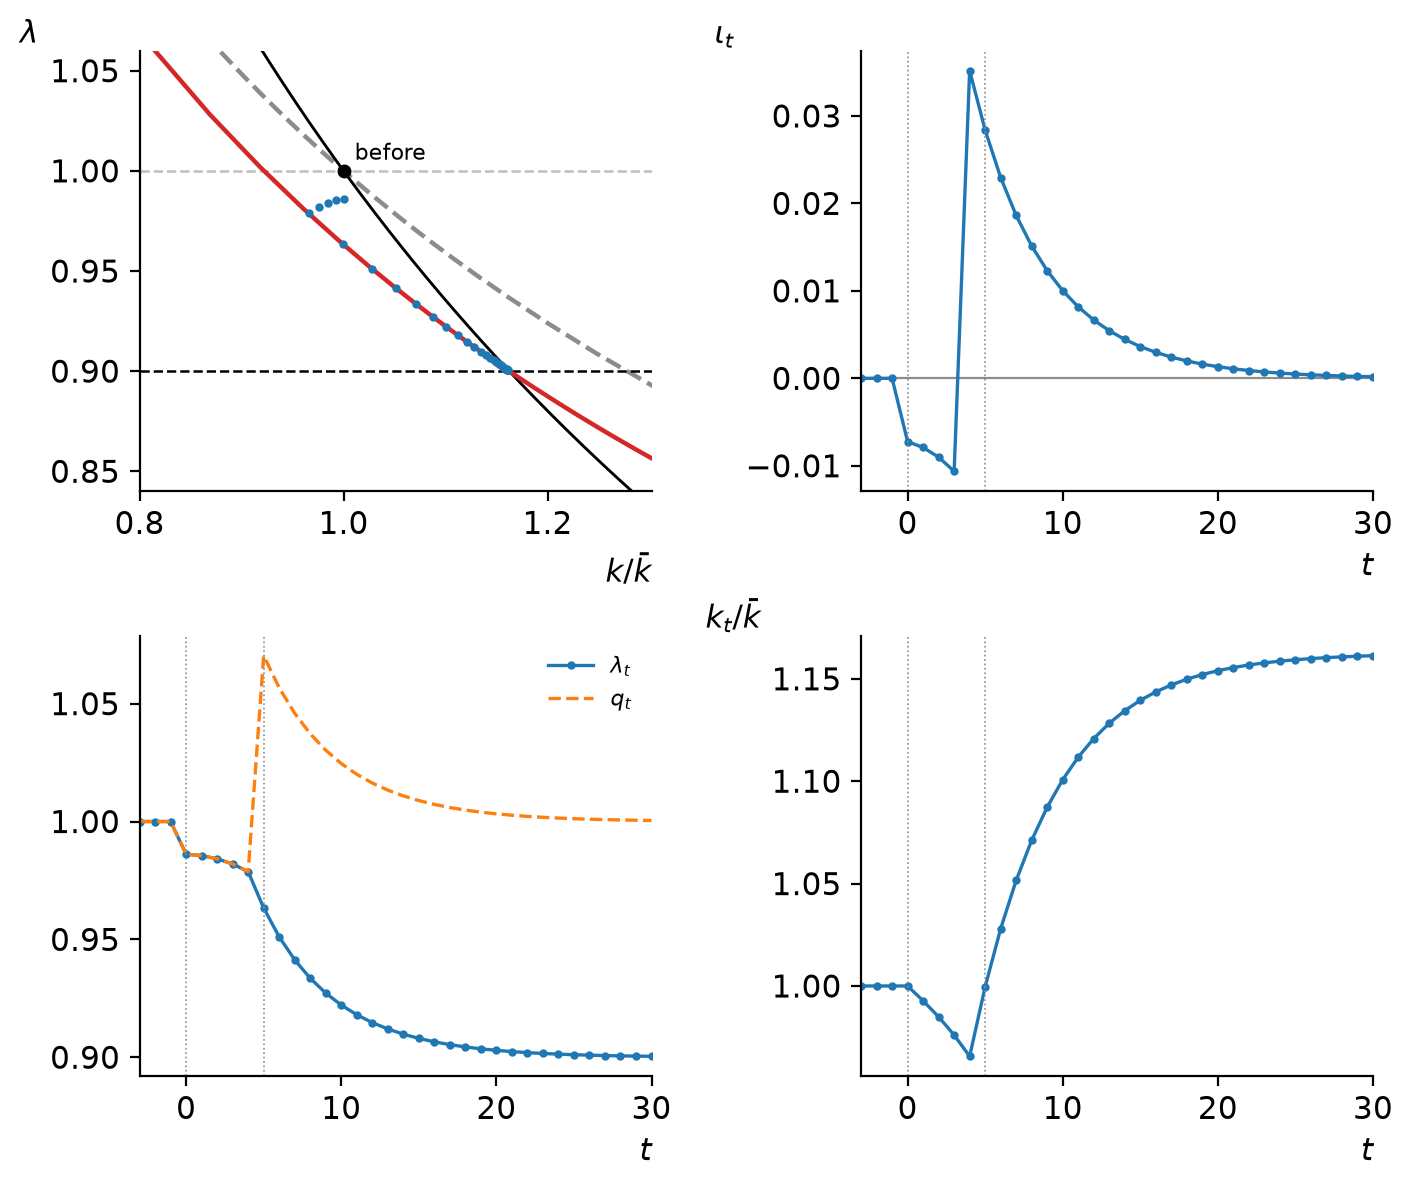

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0))
qmodel.draw_experiment(axes.ravel(), model, before, *experiments["FutureITCIncrease"], omega)
fig.tight_layout()
style.save(fig, "FutureITCIncrease")

## Announced changes

The three changes announced at 0 and in effect from 5, period by period: the net investment rate $\iota$ in percent, $\lambda$, $q$, and capital relative to its old steady state. The chapter's section on announced changes quotes these numbers. A rise in productivity and a cut in the corporate tax raise what capital earns, so investment rises at once and keeps rising until period 4, whose investment is the first capital to earn more; an investment tax credit lowers what capital costs, from the investment paid for in period 5, made in period 4, so investment falls until then and jumps.

In [ ]:
announced = {name: path for name, path in paths.items() if name.startswith("Future")}
for name, path in announced.items():
    now = path["t"] >= 0
    after, lead = experiments[name]
    k_new = model.steady_state(after["tax_free"], after["P"], after["A"])[0] / path["k0"]
    print(name)
    print("  iota, percent:", np.round(100 * path["iota"][now][:7], 2))
    print("  lambda:       ", np.round(path["lambda"][now][:7], 4))
    print("  q:            ", np.round(path["q"][now][:7], 4))
    print("  k / old kbar: ", np.round(path["k"][now][:7], 4), f" new steady state {k_new:.4f}")
first = paths["ITCIncrease"]
print(f"an ITC at once: iota at 0 {100 * first['iota'][first['t'] == 0][0]:.2f} percent")

FutureProductivityIncrease
  iota, percent: [0.99 1.07 1.2  1.4  1.66 1.35 1.1 ]
  lambda:        [1.0191 1.0197 1.0214 1.0241 1.028  1.0333 1.0271]
  q:             [1.0191 1.0197 1.0214 1.0241 1.028  1.0333 1.0271]
  k / old kbar:  [1.     1.0099 1.0207 1.0329 1.0474 1.0648 1.0792]  new steady state 1.1459
FutureCorporateTaxReduction
  iota, percent: [1.41 1.52 1.71 1.98 2.34 1.9  1.54]
  lambda:        [1.0272 1.0281 1.0304 1.0341 1.0395 1.0468 1.038 ]
  q:             [1.0272 1.0281 1.0304 1.0341 1.0395 1.0468 1.038 ]
  k / old kbar:  [1.     1.0141 1.0295 1.047  1.0677 1.0927 1.1134]  new steady state 1.2102
FutureITCIncrease
  iota, percent: [-0.72 -0.79 -0.9  -1.06  3.52  2.84  2.3 ]
  lambda:        [0.9861 0.9855 0.9842 0.982  0.9787 0.9633 0.9511]
  q:             [0.9861 0.9855 0.9842 0.982  0.9787 1.0703 1.0568]
  k / old kbar:  [1.     0.9928 0.9849 0.976  0.9657 0.9996 1.028 ]  new steady state 1.1624
an ITC at once: iota at 0 2.83 percent


How much notice the firm gets matters. With $n$ periods between the announcement and the price change, the credit applies to investment from period $n-1$; the shorter that wait, the sharper the postponement.

In [ ]:
print(" n  iota at 0   lowest before n-1   iota at n-1   k at n-1")
by_lead = {}
for n in range(2, 11):
    path = qmodel.solve(model, before, {**before, "P": 1 - 0.10}, n, omega)
    i, k = path["iota"][path["t"] >= 0], path["k"][path["t"] >= 0]
    by_lead[n] = (i[0], i[:n - 1].min(), i[n - 1], k[n - 1])
    print(f"{n:2d}  {100 * i[0]:8.2f}  {100 * i[:n - 1].min():14.2f}  {100 * i[n - 1]:14.2f}  {k[n - 1]:9.4f}")

 n  iota at 0   lowest before n-1   iota at n-1   k at n-1
 2     -1.51           -1.51            3.13     0.9849
 3     -1.18           -1.29            3.32     0.9755
 4     -0.92           -1.15            3.44     0.9695
 5     -0.72           -1.06            3.52     0.9657
 6     -0.57           -1.01            3.57     0.9632
 7     -0.45           -0.97            3.60     0.9616
 8     -0.35           -0.95            3.62     0.9606
 9     -0.28           -0.93            3.63     0.9600
10     -0.22           -0.92            3.64     0.9596


## The chapter's results

In [ ]:
future_itc, future_A = paths["FutureITCIncrease"], paths["FutureProductivityIncrease"]
iota = future_itc["iota"][future_itc["t"] >= 0]
assert np.all(iota[:4] < 0) and np.all(np.diff(iota[:4]) < 0)  # below replacement, and falling, until n - 1 = 4
assert iota[4] > 0 and iota[4] > iota[5] > 0  # the jump at n - 1, then the decline
assert future_itc["lambda"][future_itc["t"] == 0][0] < 1  # lambda jumps down at the announcement
iota = future_A["iota"][future_A["t"] >= 0]
assert np.all(iota[:5] > 0) and np.all(np.diff(iota[:5]) > 0)  # up at once and rising until the change
assert future_A["lambda"][future_A["t"] == 0][0] > 1  # lambda jumps up
tax = paths["FutureCorporateTaxReduction"]
iota = tax["iota"][tax["t"] >= 0]
assert np.all(iota[:5] > 0) and np.all(np.diff(iota[:5]) > 0)  # a future tax cut works like productivity
now = paths["ITCIncrease"]
assert now["lambda"][now["t"] == 0][0] < 1 and now["q"][now["t"] == 0][0] > 1  # an ITC lowers lambda and raises q
assert now["iota"][now["t"] == 0][0] > 0
quoted = {  # the chapter's section on announced changes: iota in percent, periods 0 to 6
    "FutureProductivityIncrease": [0.99, 1.07, 1.20, 1.40, 1.66, 1.35, 1.10],
    "FutureCorporateTaxReduction": [1.41, 1.52, 1.71, 1.98, 2.34, 1.90, 1.54],
    "FutureITCIncrease": [-0.72, -0.79, -0.90, -1.06, 3.52, 2.84, 2.30],
}
for name, values in quoted.items():
    assert np.allclose(np.round(100 * paths[name]["iota"][paths[name]["t"] >= 0][:7], 2), values), name
lam0 = {name: paths[name]["lambda"][paths[name]["t"] == 0][0] for name in quoted}
assert [round(lam0[name], 3) for name in quoted] == [1.019, 1.027, 0.986]
assert round(paths["FutureITCIncrease"]["k"][paths["FutureITCIncrease"]["t"] == 4][0], 3) == 0.966  # capital at 4
assert round(paths["FutureITCIncrease"]["q"][paths["FutureITCIncrease"]["t"] == 5][0], 2) == 1.07
assert round(100 * paths["ITCIncrease"]["iota"][paths["ITCIncrease"]["t"] == 0][0], 2) == 2.83
assert [round(100 * by_lead[2][0], 1), round(100 * by_lead[2][2], 1)] == [-1.5, 3.1]  # one period's notice
assert [round(100 * by_lead[10][0], 1), round(by_lead[10][3], 3)] == [-0.2, 0.96]  # nine periods' notice
for name, path in paths.items():  # every path ends in its new steady state
    after, lead = experiments[name]
    kbar_new = model.steady_state(after["tax_free"], after["P"], after["A"])[0] / path["k0"]
    assert abs(path["k"][-1] / kbar_new - 1) < 1e-6, name

## With sliders

Each panel redraws on fixed axes, which hold every combination of its sliders' values, so what moves is the economy, not the scale.

The phase diagram in $(k, q)$, as the cost of adjustment, the interest rate and depreciation change. Cheaper adjustment, a smaller $\omega$, makes the saddle path flatter: the firm closes more of the gap to the steady state each period, so $q$ need differ less from one.

In [ ]:
qmodel.sliders_phase(q_model, before)

A rise in productivity, announced now and taking effect after $n$ periods. With $n = 0$ it is the unexpected, immediate rise.

In [ ]:
qmodel.sliders_experiment(model, before, lambda v, size: {**v, "A": size}, qmodel.PRODUCTIVITY, "productivity")

A cut in the corporate tax rate, announced now and taking effect after $n$ periods.

In [ ]:
qmodel.sliders_experiment(model, before, lambda v, size: {**v, "tax_free": 1 - size}, qmodel.CORPORATE_TAX, "a corporate tax cut")

An investment tax credit, announced now and taking effect after $n$ periods: watch investment fall below replacement while the firm waits for the cheaper capital, whenever $n$ is more than one. With $n = 0$ or $n = 1$ the credit applies to the very first investment, and investment jumps at once.

In [ ]:
qmodel.sliders_experiment(model, before, lambda v, size: {**v, "P": 1 - size}, qmodel.ITC, "an investment tax credit")